# 实验课 07：训练后的稀疏模型，答对了多少，实际花了多少？

本课回答整个实验最直接的问题：**训练一个小模块来选择历史位置，是否改善真实回答，又是否节省时间和内存？** 本项目把这次“小规模质量与成本对照”编号为 **G4-lite**；lite 表示缩减实验范围，不是模型名字。

使用约 6 亿参数的 **Qwen3-0.6B**，原语言模型参数保持不变。新测试有 32 份 **T1 资料**：每题给出一个编号，要求返回它对应的四位数值。资料长度约 **2K，即 2048 个 token**；token 是模型处理的文本单元，可能是字、数字或词的一部分，不等于中文字符数。

**运行前预测**是：训练后的选位可能改善回答，但为选择位置付出的计算可能让它更慢；质量和速度必须分别测。测试资料与规则先固定，结果差也保留，不按新成绩重新调参。

默认执行只读已保存的 32 份资料、160 条回答及独立成本记录。CPU 是中央处理器，GPU 是图形处理器；本课不下载模型、不启动 GPU 或新的训练。

### 五种方法与共同的读取规则

注意力用 **Q 查询**与历史 **K 键**算匹配分数，按权重组合 **V 内容向量**。历史 K/V 保存为缓存。**索引器**是额外的便宜打分模块，先给位置排序，主注意力再只读取入选位置的原 K/V；这种只读部分位置的路径叫**稀疏读取**。

对少读方法，**固定集合 F**是首 4 与最近 64 个合法位置，重叠去重；**候选域**是其余合法位置。合法表示已写入、且不在当前查询的未来。下面的 k 是额外选择的候选数，`∪` 表示集合合并。

| 代号 | 实际怎么读 |
|---|---|
| **A：完整读取** | 读全部合法位置，作为比较基线 |
| **B：近期窗口** | F ∪ 最近的 k 个候选位置 |
| **C：均匀随机** | F ∪ 与内容无关地随机抽取的 k 个候选 |
| **D0：训练前索引** | F ∪ 初始索引参数打分最高的 k 个候选 |
| **D：训练后索引** | F ∪ 学习后索引参数打分最高的 k 个候选 |

**top-k**就是取分数最高的 k 个。B/C/D0/D 同题同名额；A 读全部，不受这个小预算限制。**均匀随机 C**和**随机初始化参数 D0**是两种不同条件，不能合称随机方法。

**ρ（rho）=1/8** 按请求开始时的合法长度 N0 得到 `k0=min(round(ρ×N0), 起始候选数)`；之后 k0 固定，本步 k 不能超过候选数。总读取数为 |F|+k，不等于严格八分之一。**r=32** 是索引短向量的坐标数；**P0** 表示索引用主模型位置旋转前的 Q/K，不额外对索引空间旋转。主模型的位置旋转叫 **RoPE**，用于让匹配携带原位置关系。

**自由生成**是每种方法将自己预测出的 token 送回模型继续计算，遇 **EOS（结束标记）**停止；它们自己维护后续缓存。前缀资料先完整处理并建立缓存，叫 **Prefill**；之后才从问题开始按各方法规则读取。每方法 32 次回答，共 160 次，是同一批资料上的配对结果，不是 160 份独立测试资料。

**怎样读下面的来源记录。** 一次实际执行叫一次运行（`run`），`run_id` 是它的编号；`manifest` 是随运行保存的清单，记录数据、配置和源码来自哪里。文件的哈希（`hash` / `SHA-256` / `digest`）可理解为按文件内容算出的指纹，用来核对文件是否改变，不是成绩。`commit` / `revision` 是保存代码或模型的版本编号；`dirty diff` 是运行时尚未提交的修改记录，`None` 表示此项没有内容。`tokenizer` 是把文本拆成模型输入单元的分词器。`source_hashes` 列的是源码文件指纹；`HF_HUB_OFFLINE` 表示模型库是否处于离线模式。这里保留编号是为了追溯，不需要读者记住长字符串。

下方 `scope` 说明这是同一生成器、同一提示、一个训练种子的限定结果；**种子 seed**控制可重复随机数，不是多次独立训练。`MPS` 是 PyTorch 张量计算库调用 Apple GPU 的后端，`torch` 是该库的代码名。

In [1]:
from pathlib import Path
import sys, ast, json
from IPython.display import display, Markdown, Code
ROOT=Path.cwd()
if not (ROOT/'scripts/g4lite_report.py').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
import g4lite_report as report
e=report.read_evidence();s=report.summarize(e)
print('正式run:',s['run_id'],'计算源码:',s['source_commit'])
print('新数据hash:',e['manifest']['test_data_sha256'])
print('范围:',s['scope'])

正式run: g4lite-20261018T155038Z 计算源码: 27e787fd72b4aba5f8fe51c7e756b43825a10f61
新数据hash: 1e17405456f75bedecee2863eb31faf7c34b957ce5da7134887dbfbefc825633
范围: 32 frozen new T1 documents, ~2K, one seed, same generator/template; descriptive not general capability


## 1. 三种证据，各回答一个问题

第五课的各层训练（G3b-lite）给各方法同一份完整读取产生的 Q/K/V，检查选位是否更像完整注意力的分配；这份参照分配叫“教师”，不是人工答案。第六课的真实状态诊断（G3c）强制输入同一串 token，检查各自内部表示的差异；这样的固定输入叫控制序列。本课让各方法自己生成答案，检查新题是否答对。

这32份资料在本轮训练前登记，与旧资料去重。训练只用旧48份，旧16份只作开发诊断。本轮新测试仍沿用同一种生成器与提示，不是跨模板泛化证明。固定参数、ρ=1/8、P0/r32和一个种子，测试后不再修改。

**训练资料**允许用于参数更新；**开发诊断资料**已被查看分析，不能再充当新的独立验证；**最终测试资料**在参数和规则冻结后才评分。**冻结**就是预先固定、不根据测试成绩再修改。

下面 `FROZEN_NOT_EVALUATED` 描述“登记当时已固定、尚未评分”，不表示本课现在没有结果。`quality_requests` 是自由回答请求数，`cost_sequences` 是成本对照使用的资料/输入序列数，`cost_requests` 是实际计量的成本请求数；完整资料和编号值绑定的重合数用于检查是否复用了旧样本。

In [2]:
plan=json.loads(e['files'][f"source/{s['source_commit']}/configs/g3bg4lite_test_plan.json"])
print('登记时状态:',plan['status_at_registration'])
print('资料数/重合数:',plan['count'],plan['old_prefix_overlap'],plan['old_record_bindings_overlap'])
print('完成数:',e['manifest']['completed'])
print('主体前后hash相同:',e['manifest']['body_hash_before']==e['manifest']['body_hash_after'])

登记时状态: FROZEN_NOT_EVALUATED
资料数/重合数: 32 0 0
完成数: {'quality_requests': 160, 'cost_sequences': 4, 'cost_requests': 96}
主体前后hash相同: True


## 2. 先看原回答，再解释分数

所有路径自己维护后续状态。少读方法 B/C/D0/D 共享 F 和候选名额；完整读取 A 读全部。主模型使用 **bf16/bfloat16**（每个浮点数 2 字节），D0/D 的索引参数与计算使用 **fp32/float32**（每数 4 字节），两者精度相同才便于比较训练前后。

本课按运行前固定的规则判分：从回答中取最前面的一个**独立四位数**，即它左右不紧接其他数字，再与目标值完整比较，叫 **完整匹配 exact_match**。如果先复述编号、后给正确值，仍按这条规则记错，不能事后改成“包含正确答案就算对”。

**编号回声**表示解析出来的是问题编号；**格式不足 format_error**表示没找到所需数量的四位数；**截断 truncated**表示达到输出上限而未正常结束；这些属性可能重叠。`raw_text` 保留含特殊标记的原始文本，`predicted` 是解析后的数值，`True/False` 表示判定真/假。例如 `<|im_end|>` 是结束一段消息的格式标记，不属于答案值。表中 token 数含结束标记，**中位数 median**是排序后的中间值，不是固定输出长度。

下面展示正式评分函数 `score_answer`，只用于解释规则，不改变原记录。

评分函数保留了另一任务 **T2** 的分支：给两个编号、按指定顺序返回两项四位值；本课实际只有 T1，没有产生 T2 成绩。

In [3]:
display(Markdown(report.quality_table(s)))
source=e['files'][f"source/{s['source_commit']}/src/attention_lab/g2lite_eval.py"].decode()
node=next(x for x in ast.parse(source).body if getattr(x,'name',None)=='score_answer')
display(Code(ast.get_source_segment(source,node),language='python'))

| 方法 | 完整匹配 | 格式不足 | 编号回声 | 截断 | 输出token数中位（含EOS） |
|---|---:|---:|---:|---:|---:|
| A | 21/32 | 0 | 6 | 0 | 5.0 |
| B | 1/32 | 0 | 30 | 0 | 5.0 |
| C | 0/32 | 0 | 32 | 0 | 5.0 |
| D0 | 0/32 | 0 | 31 | 0 | 5.0 |
| D | 17/32 | 0 | 8 | 0 | 5.0 |

def score_answer(task: str, targets, text: str, *, truncated: bool) -> dict:
    """Exact match = the first len(targets) standalone four-digit numbers equal the targets in order.

    Also reported: per-item correctness, whether every target appears anywhere (any order), whether a two-item answer is
    exactly the targets swapped, format_error (fewer numbers than required) and the truncation flag passed by the caller.
    """
    targets = [str(t) for t in targets]
    need = len(targets)
    if (task == "T1" and need != 1) or (task == "T2" and need != 2):
        raise ValueError(f"{task} expects {1 if task == 'T1' else 2} target(s), got {need}")
    numbers = extract_numbers(text)
    predicted = numbers[:need]
    return {
        "numbers": numbers,
        "predicted": predicted,
        "exact_match": predicted == targets,
        "item_correct": [i < len(predicted) and predicted[i] == t for i, t in enumerate(targets)],
        "targets_present_any_order": all(t in numbers for t in targets),
        "order_swapped": need == 2 and len(predicted) == 2 and predicted == list(reversed(targets)),
        "format_error": len(numbers) < need,
        "truncated": bool(truncated),
        "text": clean_text(text),
    }

## 3. 完整读取本身也会错

不要因为旧样本曾12/12，就把本批A当成必然正确。下面按同题配对，分别保留A对/D错、A错/D对和两者都错。D/A正确数之比不能代替逐题保留情况。

本课的“完整匹配”是任务输出规则下的结果，不能用来断言模型一般没有某种能力。

配对输出中的 `both_right` 是两者都对，`A_right_other_wrong` 是 A 对、另一方法错，`A_wrong_other_right` 是 A 错、另一方法对，`both_wrong` 是都错。案例名 `A_right_D_wrong` 表示 A 对而 D 错，`D_right_D0_wrong` 表示 D 对而 D0 错，`A_wrong` 表示 A 本身答错。它们是按规则挑出的解释案例，不是随机样本。

资料号 `G4lite-T1-2K-00` 表示本阶段、单值查询、约 2K、资料序号 00，不是被查询的四位编号。“准确率差 12.5 个百分点”是在两个百分数之间相减，不能解释成逐题只发生 4 次变化。

In [4]:
for method,cells in s['paired_against_A'].items():
 print(method,{k:len(v) for k,v in cells.items()})
for name,case in s['cases'].items():
 print(); print('案例类型:',name)
 if case is None: print('本批未出现');continue
 d=case['document'];print(d['doc_id'],d['question'])
 print('目标记录:',d['target_ids'][0],'→',d['targets'][0])
 for method,row in case['outputs'].items():
  print(method,'原文=',repr(row['raw_text']),'解析=',row['score']['predicted'],'对=',row['score']['exact_match'])

B {'both_right': 1, 'A_right_other_wrong': 20, 'A_wrong_other_right': 0, 'both_wrong': 11}
C {'both_right': 0, 'A_right_other_wrong': 21, 'A_wrong_other_right': 0, 'both_wrong': 11}
D0 {'both_right': 0, 'A_right_other_wrong': 21, 'A_wrong_other_right': 0, 'both_wrong': 11}
D {'both_right': 15, 'A_right_other_wrong': 6, 'A_wrong_other_right': 2, 'both_wrong': 9}

案例类型: A_right_D_wrong
G4lite-T1-2K-00 问题：编号 6688 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标记录: 6688 → 8586
A 原文= '8586<|im_end|>' 解析= ['8586'] 对= True
B 原文= '6688<|im_end|>' 解析= ['6688'] 对= False
C 原文= '6688<|im_end|>' 解析= ['6688'] 对= False
D0 原文= '6688<|im_end|>' 解析= ['6688'] 对= False
D 原文= '5866<|im_end|>' 解析= ['5866'] 对= False

案例类型: D_right_D0_wrong
G4lite-T1-2K-02 问题：编号 5854 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标记录: 5854 → 8994
A 原文= '8994<|im_end|>' 解析= ['8994'] 对= True
B 原文= '5854<|im_end|>' 解析= ['5854'] 对= False
C 原文= '5854<|im_end|>' 解析= ['5854'] 对= False
D0 原文= '5854<|im_end|>' 解析= ['5854'] 对= False
D 原文= '8994<|im_end|>' 解析= ['899

## 4. 看到名单，仍不能把它当信息来源的完整地图

**KV 组**是多个查询头共用的一张 K/V 历史表；查询头是一路并行注意力计算。“组 0”是第一组，正文层数从 1 数，代码 `[13,0]` 对应第 14 层、第 0 组。**首个答案预测处**是处理完问题最后一个 token 后，用输出分数选择第一个答案 token 的时刻。



下图是同一题首个答案预测处，D0/D在第1、14、28层、KV组0的实际原位置名单。横轴是原token位置；粉色带是整条目标记录，包含编号和标点，不等同于四个值token。

两条自由路径的问题阶段表示已各自演变，不能把选位变化全部归为同一份Q/K上参数的作用。直接未选中目标记录，也不证明该信息从未影响所读缓存；资料Prefill是完整的。

图中 `Original token position / Target record` 分别表示原始位置/目标记录。保存位置时用的 **bitset / 名单位图**是每个位置一个 0/1 标记；`.npz` 是数值数组压缩文件，`unpackbits/flatnonzero` 把它还原为被选中的原位置编号，不是再次运行选择器。

此处 `NumPy`（代码中简写 `np`）是数值数组库，仅用于解包保存的名单位图，不加载语言模型。

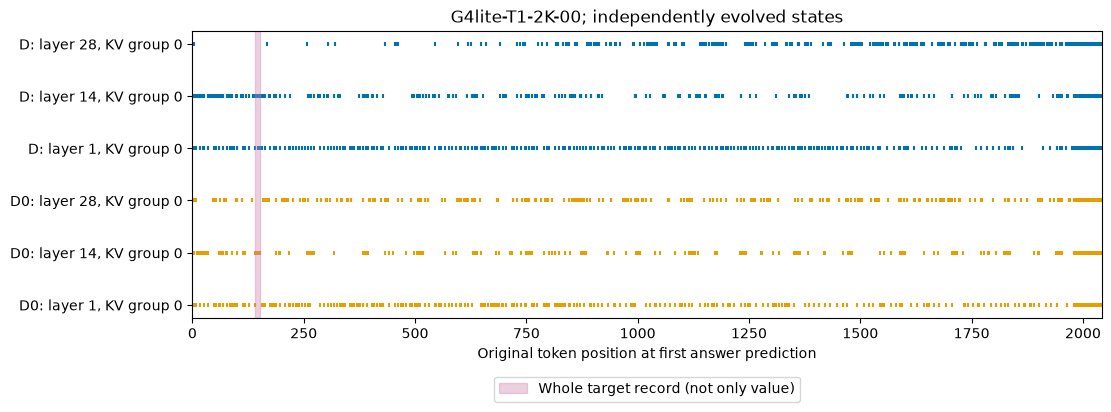

D 第14层/组0 实际全部原位置: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 34, 36, 37, 38, 40, 43, 44, 48, 54, 57, 60, 65, 68, 69, 78, 79, 82, 84, 88, 90, 99, 101, 109, 113, 120, 126, 137, 140, 141, 142, 143, 144, 146, 147, 152, 153, 155, 156, 158, 163, 171, 175, 184, 187, 196, 208, 220, 260, 261, 262, 263, 266, 267, 272, 283, 286, 296, 303, 305, 317, 318, 328, 331, 375, 382, 383, 384, 385, 389, 394, 403, 405, 415, 429, 494, 498, 505, 506, 507, 508, 512, 517, 525, 532, 540, 544, 553, 574, 577, 586, 592, 617, 627, 628, 629, 630, 631, 634, 635, 640, 652, 690, 698, 703, 704, 728, 738, 750, 751, 752, 753, 757, 762, 769, 775, 786, 789, 815, 824, 830, 836, 848, 849, 850, 851, 853, 856, 857, 859, 871, 872, 873, 884, 895, 896, 910, 911, 912, 919, 994, 995, 996, 1018, 1019, 1028, 1057, 1061, 1091, 1095, 1116, 1117, 1130, 1136, 1140, 1152, 1153, 1173, 1179, 1182, 1189, 1191, 1231, 1232, 1233, 1252, 1266, 1311, 1340, 1352, 1353, 1354, 1355, 1364, 1365, 1369,

In [5]:
import matplotlib.pyplot as plt
case=s['cases']['A_right_D_wrong']
if case is None:
 print('本批没有A对/D错案例，未伪造该类图。')
else:
 fig=report.plot_case(e,s);plt.show()
 d=case['document'];prefix=s['run_id']+'/'
 import numpy as np, io
 with np.load(io.BytesIO(e['files'][prefix+f"positions-{d['doc_id']}-D.npz"]),allow_pickle=False) as z:
  positions=np.flatnonzero(np.unpackbits(z['bitsets'],axis=-1)[13,0,:int(z['legal'])])
  print('D 第14层/组0 实际全部原位置:',positions.tolist())

## 5. 读取比例有三个不同的分母

ρ=1/8 在请求第一步决定候选名额 k0，后续固定。记 **N** 为当前合法位置数，**M=N−|F|** 为候选数量，**k** 为本步实际入选候选数：**k/M** 是候选抽取比例；**(|F|+k)/N** 才是主注意力总读取比例。两者都不能用 ρ 直接替代。

下表对应处理问题最后一个 token、预测首个答案的步骤。生成继续后 N 和 M 还会变化。输出里的 `min/median/max` 是最小/中位/最大值，`None` 或空列表表示 A 不适用候选配额，不表示读了零个位置。

索引键 **z=Wk·k_pre** 是由旋转前的 K 经新增矩阵 Wk 压缩得到的向量；保留完整 K/V 后又保存 z，意味着少读并不等于少存。下面 `make_trained_state` 是装载固定索引参数并建立独立推理状态的正式函数；`FrozenBank` 管理各层固定参数，参数身份核对防止缓存误配旧参数。

In [6]:
for method,row in s['quality'].items():
 print(method,'k0=',row['k0'],'总读取范围=',row['read_count'],'k/M=',row['candidate_extraction_ratio'],'总读取比例=',row['total_read_ratio'])
source=e['files'][f"source/{s['source_commit']}/src/attention_lab/trained.py"].decode()
node=next(x for x in ast.parse(source).body if getattr(x,'name',None)=='make_trained_state')
display(Code(ast.get_source_segment(source,node),language='python'))

A k0= [] 总读取范围= {'min': 2025, 'median': 2045.0, 'max': 2125} k/M= None 总读取比例= {'min': 1.0, 'median': 1.0, 'max': 1.0}
B k0= [249, 250, 251, 252, 253, 254, 261] 总读取范围= {'min': 317, 'median': 319.0, 'max': 329} k/M= {'min': 0.12688381137579, 'median': 0.12709285489050343, 'max': 0.12738214643931794} 总读取比例= {'min': 0.1548235294117647, 'median': 0.15611298282243524, 'max': 0.15657311669128507}
C k0= [249, 250, 251, 252, 253, 254, 261] 总读取范围= {'min': 317, 'median': 319.0, 'max': 329} k/M= {'min': 0.12688381137579, 'median': 0.12709285489050343, 'max': 0.12738214643931794} 总读取比例= {'min': 0.1548235294117647, 'median': 0.15611298282243524, 'max': 0.15657311669128507}
D0 k0= [249, 250, 251, 252, 253, 254, 261] 总读取范围= {'min': 317, 'median': 319.0, 'max': 329} k/M= {'min': 0.12688381137579, 'median': 0.12709285489050343, 'max': 0.12738214643931794} 总读取比例= {'min': 0.1548235294117647, 'median': 0.15611298282243524, 'max': 0.15657311669128507}
D k0= [249, 250, 251, 252, 253, 254, 261] 总读取范围= {'min':

def make_trained_state(model, capacity, bank, *, sparse_layers=None, mode="sparse"):
    from .qwen_wrap import LabState,make_cache
    cache=make_cache(model,capacity,with_index=True,index_dim=bank.indexes[0].r,index_dtype=torch.float32)
    return LabState(cache,bank.indexes,mode=mode,selector="index",sparse_layers=sparse_layers,cache_guard=bank.guard,canonical_order=True)

## 6. 答得短，不自动代表算得快

自由回答遇 EOS 结束，不同输出长度的总耗时不能直接比较等工作量速度。成本实验另用 4 份预定资料和**同一串 32 个控制输入 token**；每方法先执行 1 轮预热（让首次初始化影响先发生），再计量 3 轮，并轮换先后顺序。每个方法共 12 条正式计量记录。

**前向计算**是输入经过模型得到输出分数的一次计算。这里的 32 次前向对应实际输入的 32 个 token，**不是自由生成了 32 个答案 token**；第一个答案的预测已经计入问题处理阶段。

**A-step** 是与少读方法一样逐 token 处理问题的完整基线，本表简称 A；**A-best** 把已经知道的问题一次批量处理，再逐 token 处理后续输入，两种完整基线都保留。它不是事后挑最好成绩的方法。

**新缓存请求**从分配新缓存开始，包含完整资料处理、问题和 32 次控制前向；模型权重和内存管理组件已常驻，不含首次下载/加载模型。**配对比值**先对同一资料、同一轮次算“该方法耗时/A 耗时”，再取中位数，不是两个总体中位数相除。表中 `[min,max]` 是实际范围，不是置信区间。

**阶段前后同步**表示等待 GPU 完成工作再停表。资源/预算检查、日志、计分、输入搬运在计时外；D/D0 内部的参数与缓存身份检查仍计入前向，未单独测量其耗时，不能认定它是变慢的主要原因。

**KV+z MiB**只统计主缓存和索引数组的分配字节，1 MiB=2²⁰ 字节。**RSS**是进程当时驻留的物理内存；**MPS 内存快照**是 Apple GPU 后端当时的内存统计，二者都不是本方法峰值。图里 `Exact matches` 是答对数，`Seconds (median of 12)` 是 12 次等工作量测量的秒数中位，`NOT free generation` 提醒它不是自由回答耗时。

| 方法 | 新缓存请求秒，中位 [min,max] | 问题秒，中位 | 32次控制前向秒，中位 | 配对控制前向/A 中位 | KV+z MiB |
|---|---:|---:|---:|---:|---:|
| A | 1.085 [1.055,1.100] | 0.405 | 0.366 | 1.000 | 231.4 |
| A-best | 0.759 [0.713,0.800] | 0.055 | 0.375 | 1.021 | 231.4 |
| B | 1.176 [1.096,1.323] | 0.441 | 0.388 | 1.064 | 231.4 |
| C | 1.907 [1.816,2.114] | 0.822 | 0.742 | 2.033 | 231.4 |
| D0 | 1.562 [1.527,1.649] | 0.653 | 0.578 | 1.581 | 289.3 |
| D | 1.549 [1.518,1.585] | 0.647 | 0.581 | 1.579 | 289.3 |

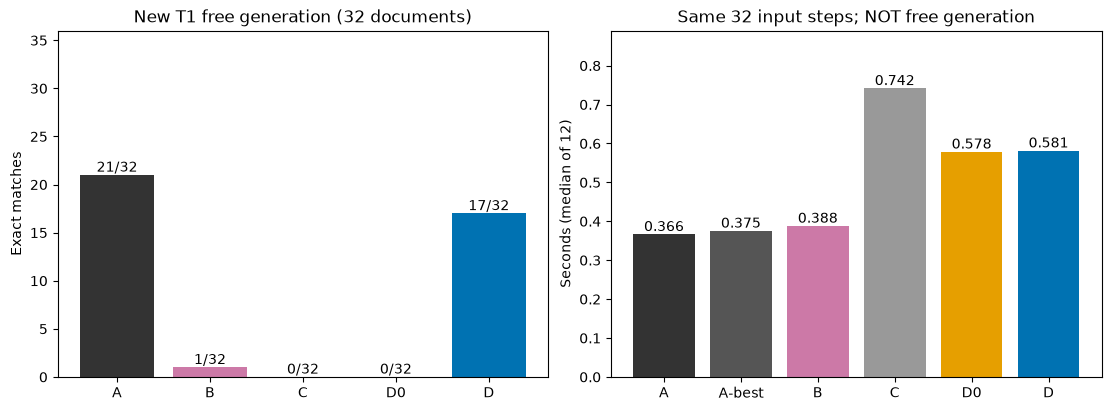

共享模型和两套索引参数常驻。KV/z为精确分配字节，RSS/MPS是快照，不称方法峰值。


In [7]:
display(Markdown(report.cost_table(s)))
report.plot(s);plt.show()
print('共享模型和两套索引参数常驻。KV/z为精确分配字节，RSS/MPS是快照，不称方法峰值。')

## 7. 把观察与结论分开

训练后D若比D0/C多答对，支持这个受限配置中的学习收益；D若比A慢，也同样保留。两者可以同时成立。G3b的条件覆盖、G3c的状态误差和本课准确率不能相互换算。

本轮没有从资料Prefill开始稀疏，没有T2/更长上下文/更多模型，没有额外轨迹修正训练。完整读取本身的错误、D仍失败的题以及同模板限制，都属于结果的一部分，不通过修改测试消除。

研究记录已随三项交付经独立复审并合入主干；PR 是代码合并申请。课程保留各阶段自己的结果和边界，阅读与文字修订不自动开启下一轮研究。

这里提到的 **条件覆盖率**是入选候选保住的教师注意力权重占候选总权重的比例；**状态误差**是在同一控制 token 下比较各方法自己的内部向量，不是答案错误比例。**T2** 是按给定顺序返回两项四位值的任务，本课没有新增它。**轨迹修正训练**是再用稀疏路径产生的状态训练索引器，本轮没有做。

末格的共享设备账累计各层训练、状态诊断、质量和成本运行（含预检/失败）的实际秒数；旧 G3a 单层训练账单独列出，不把余下预算当成必须继续实验的理由。源码 `torch`、`NumPy` 分别是张量计算库和数值数组库名称；阅读本课只处理保存数据。

In [8]:
print('累计新增设备时间(秒):',s['budget']['used_seconds'],'/',s['budget']['limit_seconds'])
print('旧G3a账单保留:',s['budget']['prior_g3a_seconds'])
print('原始质量/成本记录数:',len(e['quality']),len(e['costs']))
print('报告重建：python scripts/g4lite_report.py；默认不运行模型。')

累计新增设备时间(秒): 3897.345024082926 / 14400
旧G3a账单保留: 313.80082804203266
原始质量/成本记录数: 160 96
报告重建：python scripts/g4lite_report.py；默认不运行模型。
